# Probabilistic weather forecasting with a Gaussian head

Forecast tomorrow's temperature together with how sure the forecast is. A standard regression
network predicts a single number. Here the network predicts a **mean and a standard deviation**
for every forecast, so it can say "12 °C ± 1" on a stable day and "12 °C ± 4" when the weather is
changing.

The output layer is a [`GaussianHead`](https://anas-rz.github.io/keras-proba/api/layers/#keras_proba.layers.GaussianHead), trained
with the Gaussian negative log-likelihood ([`GaussianNLL`](https://anas-rz.github.io/keras-proba/api/losses/#keras_proba.losses.GaussianNLL)):
the loss rewards an accurate mean, and a standard deviation that matches the actual errors.

In [ ]:
# Install keras-proba, then choose a backend: "jax", "tensorflow" or "torch".
!pip install -q keras-proba
import os

os.environ["KERAS_BACKEND"] = "jax"

## Load the data

The [Jena climate](https://www.bgc-jena.mpg.de/wetter/) dataset has weather measurements every
10 minutes from 2009 to 2016. We keep one sample per hour and predict the temperature **24 hours
ahead** from the last **48 hours** of pressure, temperature, dew point, humidity and wind.
The data is split in time: 2009-2014 for training, the next year for validation and the last
year for testing.

In [2]:
import glob

import matplotlib.pyplot as plt
import numpy as np

import keras
import keras_proba

keras.utils.set_random_seed(0)
LOOKBACK, HORIZON = 48, 24  # Hours.

path = keras.utils.get_file(
    origin="https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip",
    extract=True,
)
csv = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]
data = np.genfromtxt(csv, delimiter=",", skip_header=1, usecols=(1, 2, 4, 5, 12), dtype="float32")[5::6]
data[:, 4] = np.maximum(data[:, 4], 0)  # -9999 marks missing wind measurements.
temperature = data[:, 1].copy()

train_end, val_end = int(0.7 * len(data)), int(0.85 * len(data))
features = (data - data[:train_end].mean(0)) / data[:train_end].std(0)


def windows(start, stop):
    """Inputs: the last 48 hours of features, flattened. Targets: the temperature 24 hours later."""
    ends = np.arange(max(start, LOOKBACK), stop - HORIZON + 1)
    x = np.stack([features[t - LOOKBACK : t].reshape(-1) for t in ends])
    return x, temperature[ends + HORIZON - 1][:, None]


x_train, y_train = windows(0, train_end)
x_val, y_val = windows(train_end, val_end)
x_test, y_test = windows(val_end, len(data))
print(f"{len(x_train)} training, {len(x_val)} validation and {len(x_test)} test forecasts")

48992 training, 10491 validation and 10491 test forecasts


## Build and train the model

The only change from a standard regression network is the output layer:
`GaussianHead(1)` outputs `[mean, std]` for one target, and `GaussianNLL` trains both.

In [3]:
model = keras.Sequential(
    [
        keras.Input((x_train.shape[1],)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(64, activation="relu"),
        keras_proba.layers.GaussianHead(1),
    ]
)
model.compile(optimizer="adam", loss=keras_proba.losses.GaussianNLL())
model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=256,
    callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=0,
)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


## Forecasts with uncertainty

`split_gaussian_params` splits the output into the mean and the standard deviation. A 90%
interval is the mean ± 1.645 standard deviations. The band is narrow when the weather is
predictable and widens when it is not.

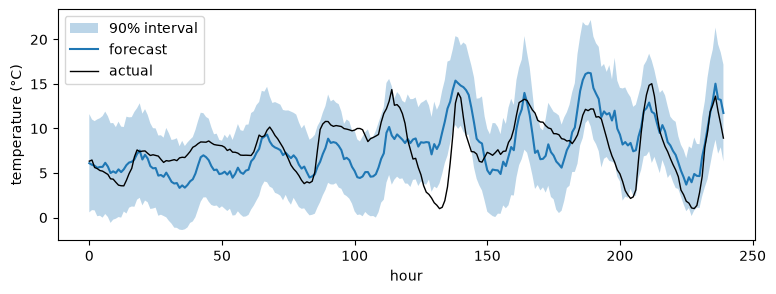

In [4]:
mean, std = keras_proba.ops.split_gaussian_params(model.predict(x_test, verbose=0))
mean, std = keras.ops.convert_to_numpy(mean)[:, 0], keras.ops.convert_to_numpy(std)[:, 0]

hours = np.arange(24 * 10)  # The first 10 days of the test year.
plt.figure(figsize=(9, 3))
plt.fill_between(hours, (mean - 1.645 * std)[hours], (mean + 1.645 * std)[hours], alpha=0.3, label="90% interval")
plt.plot(hours, mean[hours], label="forecast")
plt.plot(hours, y_test[hours, 0], "k", lw=1, label="actual")
plt.xlabel("hour")
plt.ylabel("temperature (°C)")
plt.legend()
plt.show()

## Are the intervals trustworthy?

An X% interval should contain the true temperature X% of the time. We check this on the test
year, which the model has never seen.

In [5]:
for level, z in [(0.5, 0.674), (0.8, 1.282), (0.95, 1.960)]:
    coverage = np.mean(np.abs(y_test[:, 0] - mean) <= z * std)
    print(f"{level:.0%} interval: contains the actual temperature {coverage:.1%} of the time")

50% interval: contains the actual temperature 50.3% of the time
80% interval: contains the actual temperature 80.6% of the time
95% interval: contains the actual temperature 94.8% of the time


## What we learned

- A `GaussianHead` turns a regression network into one that predicts its own uncertainty, at the
  cost of one extra output.
- The predicted intervals contain the actual temperature close to as often as they claim, often
  slightly less: the test year differs a little from the training years.
- The standard deviation only describes the noise seen during training (**aleatoric**
  uncertainty). It cannot tell when the model itself is out of its depth: see
  [Bayesian forecasting](https://anas-rz.github.io/keras-proba/examples/bayesian_forecasting/) for that, and
  [conformal forecast intervals](https://anas-rz.github.io/keras-proba/examples/conformal_forecast_intervals/) for intervals with a coverage
  guarantee.